# Module 1 Topic 4 Practical — Support Vector Machines

This practical examines margin-based classification using linear, polynomial and RBF kernels. Scaling, data splitting and plotting are supplied so the active work remains focused on kernel choice, support vectors and the trade-off controlled by C.

## Official implementation guides

These optional official guides connect this topic's concepts to standard Python implementations and the practical work. They are not required for assessment.

- [Support Vector Machines user guide](https://scikit-learn.org/stable/modules/svm.html) — connect margins, kernels and hyperparameters to scikit-learn models.
- [`StandardScaler` reference](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) — understand why feature scaling matters for distance- and margin-based models.
- [Pipeline guide](https://scikit-learn.org/stable/modules/compose.html#pipeline) — combine preprocessing and an SVM safely in one workflow.

## Learning outcomes

By the end of this practical, you should be able to:

- compare linear and nonlinear SVM kernels;
- explain why feature scaling belongs inside the pipeline;
- relate C to margin violations and support-vector count;
- select settings using validation evidence and reserve test data for final evaluation.
- implement a two-parameter validation search and refit the selected model.

### Good habits used in this notebook

- Keep preprocessing inside the pipeline to prevent leakage.
- Change one modelling choice at a time.
- Select settings with validation data, not the test set.
- Inspect boundary shape and support vectors as well as accuracy.

These habits support the topic; they are not separate programming exercises.

### If Python is new to you

- Run the notebook from top to bottom because later cells use variables created earlier.
- Begin with the short `TODO` completions, then use the completed earlier cells as patterns for the larger coding challenge.
- Read the input and expected output described above each code cell before writing code.
- Build the challenge one step at a time and run the cell after each small section.
- Ask a tutor about the first error message before changing unrelated code.
- To write an explanation, double-click the Markdown cell labelled **Write your answer**, replace the prompt, and run the cell.

The practical is designed for a two-hour session. The core student-written and adapted coding should take approximately **45–60 minutes**; interpretation and discussion are additional to that coding time.

## Setup

No external dataset download is required. The setup cell generates the reproducible teaching dataset locally, so this practical can run offline.


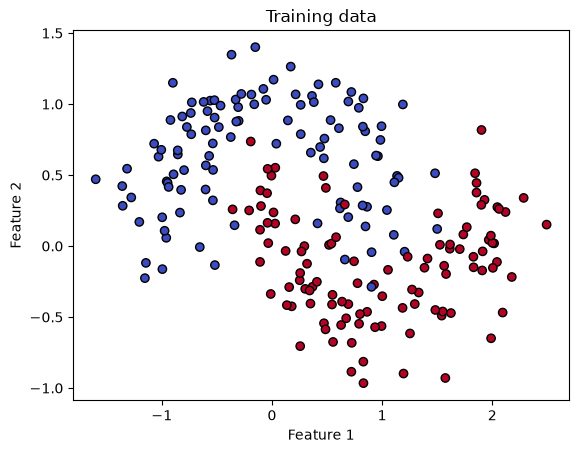

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
X, y = make_moons(n_samples=360, noise=0.24, random_state=7)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=RANDOM_STATE
)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k")
plt.title("Training data"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()

## Question 1 — Compare kernels fairly

Complete the three kernel names. `C`, scaling and data are held fixed so the kernel is the main change.

In your written answer, compare the validation accuracy and support-vector count across kernels, identify any clear underfitting, and state which kernel you would carry forward from this evidence. Explain why one validation split cannot establish universal superiority.


In [2]:
kernel_settings = {
    # TODO 1: enter 'linear'.
    "linear": {"kernel": "linear"},
    # TODO 2: enter 'poly'. Keep degree 3.
    "polynomial": {"kernel": "poly", "degree": 3},
    # TODO 3: enter 'rbf'.
    "RBF": {"kernel": "rbf", "gamma": "scale"},
}
kernel_rows = []
kernel_models = {}
for name, settings in kernel_settings.items():
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svc", SVC(C=1, **settings)),
    ])
    model.fit(X_train, y_train)
    kernel_models[name] = model
    kernel_rows.append((
        name,
        accuracy_score(y_val, model.predict(X_val)),
        model.named_steps["svc"].n_support_.sum(),
    ))
kernel_results = pd.DataFrame(kernel_rows, columns=["kernel", "validation_accuracy", "support_vectors"])
display(kernel_results)

,kernel,validation_accuracy,support_vectors
0,linear,0.833333,73
1,polynomial,0.805556,73
2,RBF,0.916667,71


### Write your answer — Question 1

Compare the kernels using validation accuracy and support-vector count, identify underfitting, choose a candidate kernel, and state the limitation of this evidence.


RBF kernel has the highest validation accuracy score (0.916667) with the lowest support vector count (71), the linear kernel follows second with a validation accuracy score of 0.833 and a support vector count of 73, and poly has the lowest validation accuracy score (0.805556) and a support vector count of 73.

Underfitting occurs in the polynomial kernel because it has the lowest validation accuracy score with similar support vector count to linear. It suggests that the polynomial kernel isn't the right functional shape for this decision boundary. In addition, we can see that the linear kernel underfit as well, there are certain nonlinear structure in the data that the linear kernel cannot capture.

RBF has the highest validation accuracy score with the fewest support vector count, and has no underfitting signals. So I'd choose the RBF kernel moving forward.

One validation split cannot establish universal superiority because SVMs can be sensitive to which points ends up in the train and validation set, a different split might produce different validation accuracy scores. The current split shows us that RBF is the best performer, not that it would win consistently across repeated splits.

It's best that in the future that we use multiple training and validation sets to determine which kernel performs the best, such that we can take the average and see which kernel performs consistently.

## Question 2 — Inspect decision boundaries

Run the supplied helper. The large outlined circles identify the training observations used as support vectors.

In your written answer, identify a boundary that underfits, describe any unnecessary complexity, explain how support vectors determine the fitted boundary, and explain why boundary shapes in regions with little data should be interpreted cautiously.


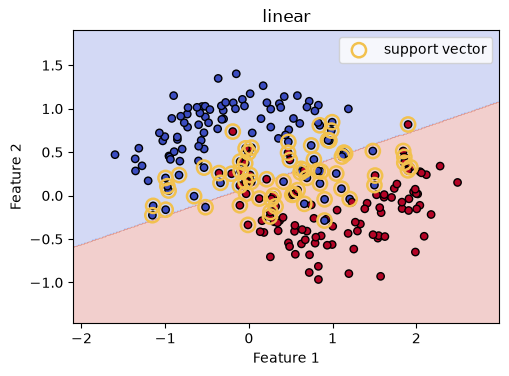

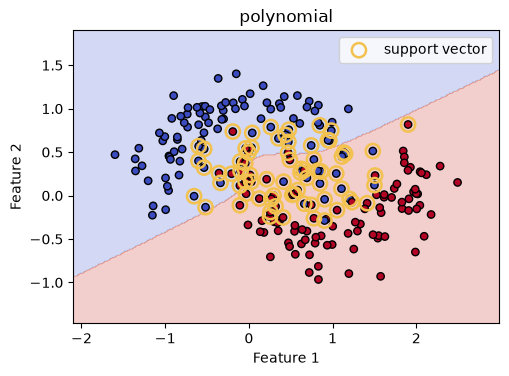

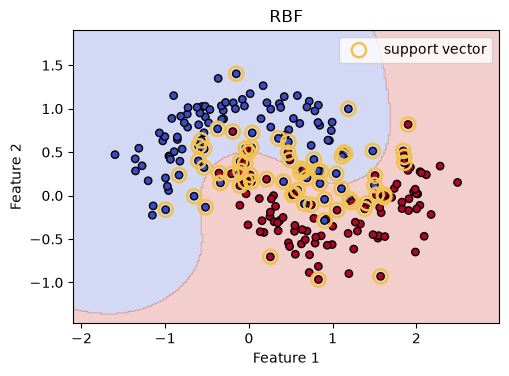

In [3]:
def plot_boundary(model, title):
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 240),
        np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 240),
    )
    labels = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(5.5, 3.8))
    plt.contourf(xx, yy, labels, alpha=0.25, cmap="coolwarm")
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k", s=28)
    support_indices = model.named_steps["svc"].support_
    plt.scatter(
        X_train[support_indices, 0], X_train[support_indices, 1],
        facecolors="none", edgecolors="#F2C14E", linewidths=1.8,
        s=105, label="support vector"
    )
    plt.title(title); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.legend(loc="best")
    plt.show()

for name, model in kernel_models.items():
    plot_boundary(model, name)

### Write your answer — Question 2

Discuss underfitting, unnecessary boundary complexity, the role of the outlined support vectors, and uncertainty in regions with few observations.


Polynomial kernel can be seen to underfit the data because the boundary does curve, but not that much to fit the data points. We can see the linear kernel underfits the data as well because the boundary doesn't curve at all because it cannot follow the curved classes.

Within the RBF kernel's plot, in the bottom left corner, the boundary dips downwards despite not having any data points in the area. This creates unecessary boundary complexity because the kernel creates a specific boundary shape but there isn't actually any data points near the curve to support the curved boundary. This is caused by how certain points are pulling the boundary into shapes that doesn't really justify the entire dataset, bends from observed data should not be over-interpreted. Visual complexity alone isn't evidence of better generalization. 

The large gold outlines identify the support vectors that are responsible for defining the fitted margin and boundary. They're training observations that either lie on or inside the boundary. Different kernels identify different support vector sets becauase they represent similarity and geometry differently. Observations that are not support vectors doesn't directly determine the final SVM solution for the fitted settings.

## Question 3 — Tune C using validation data

Complete the candidate list. Smaller `C` tolerates more violations; larger `C` penalises them more strongly.

In your written answer, report the preferred `C` from the validation results, describe how validation accuracy and support-vector count change across the candidates, and explain why `C` should not be selected using the test set.


In [4]:
# TODO 4: compare 0.1, 1 and 100.
c_candidates = [0.1, 1, 100]
c_rows = []
c_models = {}
for C in c_candidates:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svc", SVC(kernel="rbf", gamma="scale", C=C)),
    ])
    model.fit(X_train, y_train)
    c_models[C] = model
    c_rows.append((C, accuracy_score(y_val, model.predict(X_val)), model.named_steps["svc"].n_support_.sum()))
c_results = pd.DataFrame(c_rows, columns=["C", "validation_accuracy", "support_vectors"])
display(c_results)

,C,validation_accuracy,support_vectors
0,0.1,0.861111,120
1,1.0,0.916667,71
2,100.0,0.902778,36


### Write your answer — Question 3

Report the validation-selected `C`, describe the accuracy/support-vector pattern, and explain why the test set is not used for this choice.


The preferred C here is C=1 since it gives the highest validation accuracy (0.916667). The validation accuracy score for C=0.1 is 0.8611 with 120 support vectors, and for C=100 is 0.902778 with 36 support vectors.

As C increases from 0.1 to 100, the kernel tolerates fewer margin violations. And therefore, the support vector count dropped from 120 to 71 and then 36. Because larger C fits the training points more strictly, so fewer observations determine a tighter fit. At C=100, the validation accuracy score is 0.902778 and it's lower than C=1, and this shows that at C=100, the kernel has started to overfit the individual training points rather than the general boundary. So having a bigger C doesn't guarantee a better validation accuracy score.

C shouldn't be selected using the test set because the test set is used to give an unbiased estimate of the kernel's generalization, and it is used to simulate how the kernel performs on new unseen data. If the test set is repeatedly used to select the best C, you're fitting C to the test set, which means that the validation accuracy score might overestimate how the kernel performs for actual new data.

## Question 4 — Coding challenge: search C and gamma together

Real model selection often involves interacting hyperparameters. Build a two-dimensional validation search for an RBF SVM using four `C` values and three `gamma` values.

For every candidate, fit the same leakage-safe pipeline and record validation accuracy and support-vector count. Sort the results and select the highest validation accuracy, using fewer support vectors only as a tie-breaker. Do not use the test set during this search.

In your written answer, report the selected `C` and `gamma`, describe what happens at very small or large values, and explain why this finite grid and single validation split do not guarantee universally best settings.


In [5]:
# Coding challenge: search C and gamma together using validation data only.
c_grid = [0.1, 1, 10, 100]
gamma_grid = [0.1, 1, 10]
search_rows = []

# TODO 5: write the nested loops over C and gamma.
for C in c_grid:
    for gamma in gamma_grid:
        # TODO 6: create the scaling + RBF SVM pipeline.
        candidate = Pipeline([
            ("scale", StandardScaler()),
            ("svc", SVC(kernel="rbf", C=C, gamma=gamma)),
        ])
        # TODO 7: fit on training data and predict validation data.
        candidate.fit(X_train, y_train)
        validation_prediction = candidate.predict(X_val)

        # TODO 8: append a dictionary containing C, gamma, validation
        # accuracy and total support-vector count.
        search_rows.append({
            "C": C,
            "gamma": gamma,
            "validation_accuracy": accuracy_score(y_val, validation_prediction),
            "support_vectors": candidate.named_steps["svc"].n_support_.sum(),
        })

# TODO 9: create and sort a DataFrame: highest accuracy first, then
# fewer support vectors. Display every candidate.
search_results = pd.DataFrame(search_rows)
search_results = search_results.sort_values(
    ["validation_accuracy", "support_vectors"], ascending=[False, True]
).reset_index(drop=True)
display(search_results)

# TODO 10: extract the selected C and gamma from the first row.
best_c = float(search_results.loc[0, "C"])
best_gamma = float(search_results.loc[0, "gamma"])
print("Selected C:", best_c, "Selected gamma:", best_gamma)

,C,gamma,validation_accuracy,support_vectors
0,1.0,1.0,0.958333,64
1,10.0,1.0,0.930556,45
2,1.0,10.0,0.930556,123
3,0.1,10.0,0.930556,216
4,100.0,1.0,0.916667,31
5,100.0,0.1,0.916667,58
6,100.0,10.0,0.916667,99
7,10.0,10.0,0.902778,109
8,0.1,1.0,0.902778,129
9,10.0,0.1,0.861111,73


Selected C: 1.0 Selected gamma: 1.0


### Write your answer — Question 4

Report the selected `C` and `gamma`, interpret small and large settings using validation performance or support vectors, and state the limits of the search.


The best combination is C=1 and Gamma=1 with a validation score of 0.958 and uses 64 supoprt vectors.

The table demonstrates that C and gamma interact: C controls the penalty for violations, while gamma controls how locally an RBF influence acts.

Small gamma (gamma=0.1) combined with small C (c=0.1) makes the kernel underfit the data, demonstrated by the low validation accuracy score of 0.819444 and the use of 133 support vectors. A small gamma means each point's influence is wide, which can make the boundary underfit the dataset and generalize too widely to capture the curves the dataset has. 

Large gamma (gamma=10) combined with small C (c=0.1) raises the support vector count a lot up to 216, however it still hasn't achieve the best validation accuracy score (0.930556). Big gamma means the boundary will focus on wrapping around the individual points, which can cause the kernel to overfit the dataset even though the validation accuracy score is moderate.

his finite grid and single validation split doesn't guarantee universally best settings because the same validation observation are compared repeatedly. Cross-validation would provide a more stable estimate, and no finite grid guarantees universally best settings.

## Question 5 — Final unbiased evaluation

After choosing the kernel, `C` and `gamma` from validation results, refit on all training/validation data and evaluate once on the untouched test set.

In your written answer, report the fixed settings and final test accuracy. Explain why the test set is used only once and how repeatedly selecting settings from test performance would bias the evaluation.


In [6]:
final_model = Pipeline([
    ("scale", StandardScaler()),
    # TODO 11: use the selected best_c and best_gamma.
    ("svc", SVC(kernel="rbf", C=best_c, gamma=best_gamma)),
])
# TODO 12: fit on all training/validation data and evaluate the test set once.
final_model.fit(X_trainval, y_trainval)
final_test_accuracy = accuracy_score(y_test, final_model.predict(X_test))
print(f"Final test accuracy: {final_test_accuracy:.3f}")

Final test accuracy: 0.958


### Write your answer — Question 5

Report the fixed settings and final test accuracy. Explain why the test set is evaluated once and how test-driven model selection would bias the result.


Using the selected setting from the part 4 (C=1, gamma=1), refitting on the training and validation set gives a final test accuracy of 0.958. 

The test set is only used once at the end after the modeling choices are fixed because it's meant to simulate real unseen data. If you repeatedly use the test set to find the best settings of C or gamma, you'd be fitting the test set and it would stop being an unbiased measure of generalization of the kernel, turning the test set into validation data. The reported accuracy would perform more optimistically on the test set than on actual new and unseen data.

## Optional extensions

These are not required. Use them only after completing the core work:

- Use cross-validation to compare the candidate settings.
- Plot the selected model's support vectors and relate them to the margin and difficult observations.

In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv_rows = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for C in c_grid:
  for gamma in gamma_grid:
    candidate = Pipeline([
      ("scale", StandardScaler()),
      ("svc", SVC(kernel="rbf", C=C, gamma=gamma)),
    ])
    scores = cross_val_score(candidate, X_trainval, y_trainval, cv=cv, scoring="accuracy")
    cv_rows.append({
      "C": C,
      "gamma": gamma,
      "cv_mean_accuracy": scores.mean(),
      "cv_std_accuracy": scores.std(),
    })

cv_results = pd.DataFrame(cv_rows)
cv_results = cv_results.sort_values(
  ["cv_mean_accuracy", "cv_std_accuracy"], ascending=[False, True]
).reset_index(drop=True)
display(cv_results)

cv_best_c = float(cv_results.loc[0, "C"])
cv_best_gamma = float(cv_results.loc[0, "gamma"])
print("CV-selected C:", cv_best_c, "CV-selected gamma:", cv_best_gamma)

,C,gamma,cv_mean_accuracy,cv_std_accuracy
0,1.0,10.0,0.948034,0.043523
1,10.0,1.0,0.944465,0.029695
2,1.0,1.0,0.941016,0.027928
3,0.1,10.0,0.937568,0.035458
4,100.0,1.0,0.930551,0.039374
5,10.0,10.0,0.913249,0.026562
6,100.0,0.1,0.913249,0.032592
7,0.1,1.0,0.913249,0.034368
8,100.0,10.0,0.896007,0.039084
9,10.0,0.1,0.875257,0.046287


CV-selected C: 1.0 CV-selected gamma: 10.0


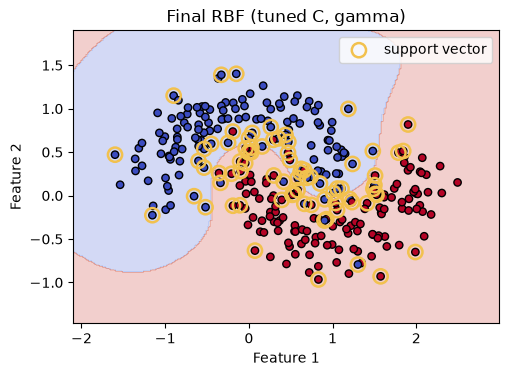

In [8]:
def plot_boundary_final(model, X_data, y_data, title):
  xx, yy = np.meshgrid(
    np.linspace(X_data[:, 0].min()-0.5, X_data[:, 0].max()+0.5, 240),
    np.linspace(X_data[:, 1].min()-0.5, X_data[:, 1].max()+0.5, 240),
  )
  labels = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
  plt.figure(figsize=(5.5, 3.8))
  plt.contourf(xx, yy, labels, alpha=0.25, cmap="coolwarm")
  plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap="coolwarm", edgecolor="k", s=28)
  support_indices = model.named_steps["svc"].support_
  plt.scatter(
    X_data[support_indices, 0], X_data[support_indices, 1],
    facecolors="none", edgecolors="#F2C14E", linewidths=1.8,
    s=105, label="support vector"
  )
  plt.title(title); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
  plt.legend(loc="best")
  plt.show()

plot_boundary_final(final_model, X_trainval, y_trainval, "Final RBF (tuned C, gamma)")

The single-split search selected C=1.0, gamma=1.0, while 5-fold cross-validation selected C=1.0, gamma=10.0. This shows that the gamma choice differed between the two methods. On the single split, gamma=1.0 outperformed gamma=10.0 by 2.7 points, but averaged across 5 folds this ranking reversed. This is direct evidence for the limitation mentioned earlier: a single validation split does not guarantee the same ranking as a multi-split evaluation. In addition, gamma=10.0 configurations showed higher fold-to-fold variance in the CV results, consistent with the notion that higher gamma produces a more localized decision boundary that is more sensitive to exactly which points fall into which split

## Summary

This practical connected the week’s ideas:

- kernels control the shape of the decision boundary;
- C controls the margin–violation trade-off;
- pipelines prevent preprocessing leakage;
- validation selects settings and the test set estimates final generalisation.
- structured validation searches expose interactions between hyperparameters.